# 02. Modelo de risco de atraso

**Objetivo:** estimar, para cada cliente da carteira, a probabilidade de atrasar mais de 15 dias no período de previsão, e usar essa probabilidade para ordenar a cobrança.

**Como o modelo é avaliado:** a base é desbalanceada (1,7% de clientes em risco), então a acurácia não serve. O critério principal é a capacidade de colocar os clientes de risco no topo da lista: quanto dos casos de risco, e do valor deles, fica nos 10% e 20% de clientes com maior score.

**Variáveis:** o modelo usa só o comportamento de pagamento até a data de corte. Os dados cadastrais são do pedido atual, posterior ao corte; a seção 8.1 mostra que eles não melhoram o modelo, e por isso ficam de fora.

**Etapas:** preparação das variáveis, divisão entre treino e teste, comparação de três abordagens, avaliação no teste, leitura do que o modelo aprendeu, teste com o critério de 30 dias, teste com os dados cadastrais, calibração das probabilidades e gravação dos scores no banco.

## 1. Preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
sys.path.append(str(ROOT / "src"))

from db import get_engine
from modeling import (BEHAVIOR_FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, capture_at_top,
                      gains_curve, load_client_base, prepare_features)

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42  # semente fixa: os resultados saem iguais a cada execução
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Dados e variáveis

As variáveis são montadas em `src/modeling.py`. O modelo usa as de comportamento de pagamento até o corte; as cadastrais também são preparadas, para a comparação da seção 8.1. Ajustes aplicados:
- valores monetários (renda e valor do histórico) em logaritmo, para clientes muito grandes não dominarem o modelo;
- atrasos limitados a 365 dias, porque parcelas em aberto há anos geram valores extremos;
- tipos de renda raros agrupados em "Other" e clientes sem cadastro com categoria própria.

O valor a receber no período **não** entra como variável: ele é usado só para medir o valor em risco.

In [2]:
df = load_client_base()
X = prepare_features(df)
y = df["target_late_15"].astype(int)
value = df["window_amount_due"]

print(f"{len(X):,} clientes, {len(BEHAVIOR_FEATURES)} variáveis de comportamento no modelo, {y.mean():.2%} em risco")
X.head()

156,333 clientes, 11 variáveis de comportamento no modelo, 1.68% em risco


,hist_contracts,hist_installments,log_hist_amount_due,hist_pct_late,hist_pct_late_15,hist_max_days_late,hist_avg_days_late,hist_pct_split_payment,recent_installments,recent_pct_late,recent_max_days_late,has_profile,log_income,age_years,years_employed,no_current_job,region_rating,income_type,education_level
0,1.000,7.000,11.078,0.000,0.000,-22.000,-25.290,0.000,6.000,0.000,-23.000,1.000,12.219,25.000,1.700,0.000,2.000,Working,Secondary / secondary special
1,4.000,50.000,13.301,0.320,0.000,12.000,-2.040,0.060,6.000,0.000,-6.000,1.000,11.708,54.000,8.300,0.000,2.000,Working,Secondary / secondary special
2,3.000,24.000,13.565,0.042,0.042,365.000,43.790,0.042,5.000,0.000,-4.000,1.000,11.503,46.000,4.300,0.000,2.000,State servant,Secondary / secondary special
3,4.000,24.000,12.488,0.000,0.000,-1.000,-7.670,0.000,2.000,0.000,-6.000,1.000,12.049,37.000,8.600,0.000,2.000,Commercial associate,Higher education
4,2.000,39.000,13.836,0.410,0.026,365.000,23.820,0.231,6.000,1.000,6.000,1.000,11.631,55.000,NaN,1.000,2.000,Pensioner,Secondary / secondary special


## 3. Divisão entre treino e teste

70% dos clientes para treinar e 30% para testar. O teste fica guardado até o fim e só é usado para a avaliação final, como uma prova que o modelo nunca viu. A divisão é estratificada: a proporção de clientes em risco é a mesma nos dois grupos.

In [3]:
X_train, X_test, y_train, y_test, value_train, value_test = train_test_split(
    X, y, value, test_size=0.30, stratify=y, random_state=SEED
)
print(f"Treino: {len(X_train):,} clientes ({y_train.mean():.2%} em risco)")
print(f"Teste:  {len(X_test):,} clientes ({y_test.mean():.2%} em risco)")

Treino: 109,433 clientes (1.68% em risco)
Teste:  46,900 clientes (1.68% em risco)


## 4. As três abordagens

1. **Regra simples (referência):** ordena os clientes pelo % de parcelas atrasadas nos 6 meses antes do corte, o melhor sinal da análise exploratória. É o que uma equipe de cobrança faria sem modelo. Um modelo só se justifica se superar essa regra.
2. **Regressão logística:** modelo linear e interpretável.
3. **Gradient boosting:** combina muitas árvores de decisão e captura relações não lineares entre as variáveis.

Os dois modelos usam o mesmo pré-processamento: campos vazios preenchidos com a mediana (com uma coluna indicando que estava vazio) e variáveis padronizadas. O **peso de classe** (`class_weight="balanced"`) faz cada cliente em risco valer mais no treino, para o modelo não ignorar os poucos casos.

In [4]:
def rule_score(X):
    """Regra de referência: % de atraso recente; desempata pelo % de atraso no histórico."""
    return X["recent_pct_late"].fillna(0) + X["hist_pct_late"] / 1000


def make_preprocess(numeric, categorical=()):
    """Preenche vazios com a mediana, padroniza números e transforma categorias em colunas 0/1."""
    steps = [("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), list(numeric))]
    if categorical:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(categorical)))
    return ColumnTransformer(steps)


preprocess = make_preprocess(BEHAVIOR_FEATURES)

models = {
    "Regressão logística": Pipeline([
        ("prep", preprocess),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ]),
    "Gradient boosting": Pipeline([
        ("prep", preprocess),
        ("model", HistGradientBoostingClassifier(
            class_weight="balanced", learning_rate=0.05, max_iter=300, random_state=SEED)),
    ]),
}

## 5. Comparação por validação cruzada

Antes de olhar o teste, os modelos são comparados só dentro do treino: ele é dividido em 5 partes, e cada modelo é treinado 5 vezes, sempre avaliado na parte que ficou de fora. Isso escolhe o modelo sem usar o teste.

Métricas:
- **AUC:** a chance de um cliente em risco receber score maior que um cliente sem risco (0,5 é sorteio, 1,0 é perfeito);
- **Precisão média (AP):** resume a qualidade do topo da lista; para referência, um score aleatório teria AP igual à taxa de risco, cerca de 0,017.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    cv_rows.append({
        "modelo": name,
        "AUC": scores["test_roc_auc"].mean(),
        "AP": scores["test_average_precision"].mean(),
    })

rule_train = rule_score(X_train)
cv_rows.append({"modelo": "Regra simples", "AUC": roc_auc_score(y_train, rule_train),
                "AP": average_precision_score(y_train, rule_train)})

cv_table = pd.DataFrame(cv_rows).set_index("modelo")
best_name = cv_table.drop("Regra simples")["AP"].idxmax()
print(f"Modelo escolhido pela validação cruzada: {best_name}")
cv_table

Modelo escolhido pela validação cruzada: Regressão logística


,AUC,AP
modelo,,
Regressão logística,0.755,0.110
Gradient boosting,0.755,0.109
Regra simples,0.724,0.066


## 6. Avaliação no teste

Os modelos são treinados no treino inteiro e avaliados uma única vez no teste. Além de AUC e AP, a tabela mostra a pergunta de negócio: se a cobrança contatar só os 10% ou 20% de clientes com maior score, quanto dos casos de risco e do valor em risco ela alcança.

In [6]:
test_scores = {"Regra simples": rule_score(X_test).to_numpy()}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_scores[name] = model.predict_proba(X_test)[:, 1]

rows = []
for name, score in test_scores.items():
    cases_10, value_10 = capture_at_top(y_test, score, value_test, 0.10)
    cases_20, value_20 = capture_at_top(y_test, score, value_test, 0.20)
    rows.append({
        "modelo": name,
        "AUC": roc_auc_score(y_test, score),
        "AP": average_precision_score(y_test, score),
        "casos no top 10%": cases_10,
        "valor no top 10%": value_10,
        "casos no top 20%": cases_20,
        "valor no top 20%": value_20,
    })
test_table = pd.DataFrame(rows).set_index("modelo")
test_table

,AUC,AP,casos no top 10%,valor no top 10%,casos no top 20%,valor no top 20%
modelo,,,,,,
Regra simples,0.714,0.062,0.385,0.361,0.539,0.540
Regressão logística,0.737,0.093,0.433,0.395,0.556,0.531
Gradient boosting,0.724,0.099,0.433,0.417,0.560,0.549


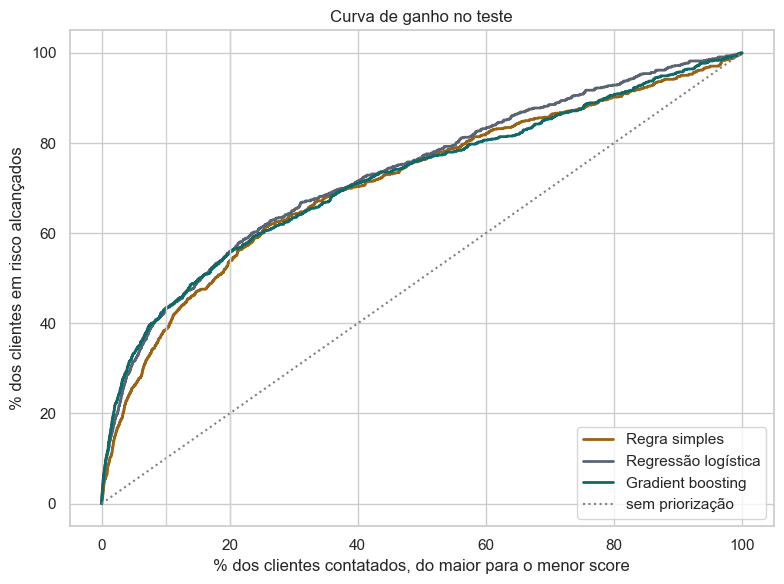

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = {"Regra simples": "#9a6212", "Regressão logística": "#5a6473", "Gradient boosting": "#0d6a68"}
for name, score in test_scores.items():
    x_curve, y_curve = gains_curve(y_test, score)
    ax.plot(x_curve * 100, y_curve * 100, label=name, color=colors[name], linewidth=2)
ax.plot([0, 100], [0, 100], color="grey", linestyle=":", label="sem priorização")
for share in (10, 20):
    ax.axvline(share, color="lightgrey", linewidth=1)
ax.set_xlabel("% dos clientes contatados, do maior para o menor score")
ax.set_ylabel("% dos clientes em risco alcançados")
ax.set_title("Curva de ganho no teste")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_curva_de_ganho.png", dpi=150)
plt.show()

## 7. O que o modelo aprendeu

Importância por permutação: embaralha uma variável de cada vez no teste e mede quanto a qualidade do topo da lista (AP) piora. Quanto maior a queda, mais o modelo depende daquela variável.

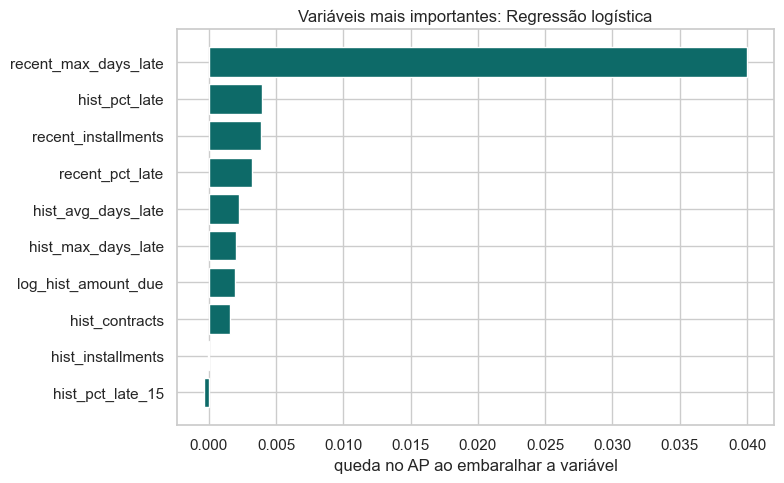

,queda no AP
variável,
recent_max_days_late,0.040
hist_pct_late,0.004
recent_installments,0.004
recent_pct_late,0.003
hist_avg_days_late,0.002
hist_max_days_late,0.002
log_hist_amount_due,0.002
hist_contracts,0.002
hist_installments,-0.000


In [8]:
best_model = models[best_name]
sample = X_test[BEHAVIOR_FEATURES].sample(n=min(20_000, len(X_test)), random_state=SEED)
importance = permutation_importance(
    best_model, sample, y_test.loc[sample.index],
    scoring="average_precision", n_repeats=5, random_state=SEED,
)
importance_table = (
    pd.DataFrame({"variável": sample.columns, "queda no AP": importance.importances_mean})
    .sort_values("queda no AP", ascending=False)
    .set_index("variável")
)

top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["queda no AP"], color="#0d6a68")
ax.set_xlabel("queda no AP ao embaralhar a variável")
ax.set_title(f"Variáveis mais importantes: {best_name}")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_importancia_variaveis.png", dpi=150)
plt.show()

importance_table

## 8. Análise de sensibilidade: critério de 30 dias

O mesmo modelo é treinado com o alvo de atraso acima de 30 dias, com a mesma divisão de treino e teste. Se as conclusões se mantiverem, a escolha de 15 dias não é o que sustenta o resultado.

In [9]:
y30 = df["target_late_30"].astype(int)
y30_train, y30_test = y30.loc[X_train.index], y30.loc[X_test.index]

model_30 = clone(best_model).fit(X_train, y30_train)
score_30 = model_30.predict_proba(X_test)[:, 1]

sens_rows = []
for label, y_eval, score in [("15 dias", y_test, test_scores[best_name]), ("30 dias", y30_test, score_30)]:
    cases_10, value_10 = capture_at_top(y_eval, score, value_test, 0.10)
    sens_rows.append({
        "critério": label,
        "taxa de risco": y_eval.mean(),
        "AUC": roc_auc_score(y_eval, score),
        "AP": average_precision_score(y_eval, score),
        "casos no top 10%": cases_10,
        "valor no top 10%": value_10,
    })
sens_table = pd.DataFrame(sens_rows).set_index("critério")
sens_table

,taxa de risco,AUC,AP,casos no top 10%,valor no top 10%
critério,,,,,
15 dias,0.017,0.737,0.093,0.433,0.395
30 dias,0.007,0.775,0.073,0.521,0.447


## 8.1. Os dados cadastrais ajudam?

O cadastro (renda, idade, emprego, tipo de renda, escolaridade e região) é do pedido atual, posterior à data de corte. O mesmo modelo é treinado com o comportamento **mais** o cadastro e comparado com o modelo só de comportamento no mesmo teste. Se o cadastro não melhorar o resultado, ele fica de fora: evita usar informação posterior ao corte e o modelo passa a julgar o cliente só pelo que ele fez.

In [10]:
model_with_profile = Pipeline([
    ("prep", make_preprocess(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
    ("model", clone(best_model.named_steps["model"])),
]).fit(X_train, y_train)
score_with_profile = model_with_profile.predict_proba(X_test)[:, 1]

profile_rows = []
for label, score in [("só comportamento (modelo final)", test_scores[best_name]),
                     ("comportamento + cadastro", score_with_profile)]:
    cases_10, value_10 = capture_at_top(y_test, score, value_test, 0.10)
    cases_20, _ = capture_at_top(y_test, score, value_test, 0.20)
    profile_rows.append({"variáveis": label, "AUC": roc_auc_score(y_test, score),
                         "AP": average_precision_score(y_test, score),
                         "casos no top 10%": cases_10, "valor no top 10%": value_10,
                         "casos no top 20%": cases_20})
profile_table = pd.DataFrame(profile_rows).set_index("variáveis")
profile_table

,AUC,AP,casos no top 10%,valor no top 10%,casos no top 20%
variáveis,,,,,
só comportamento (modelo final),0.737,0.093,0.433,0.395,0.556
comportamento + cadastro,0.745,0.096,0.431,0.396,0.569


## 9. Calibração das probabilidades

O peso de classe ajuda a ordenar, mas infla as probabilidades: o modelo passa a "achar" que o risco é maior do que realmente é. Para calcular o valor esperado em risco (probabilidade × valor a receber), a probabilidade precisa ser realista. A calibração isotônica ajusta os scores para que, num grupo de clientes com probabilidade de 5%, cerca de 5% de fato atrasem.

A tabela divide o teste em 10 grupos (decis) pelo score e compara a probabilidade média prevista com a taxa real de cada grupo.

In [11]:
calibrated = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=cv)
calibrated.fit(X_train, y_train)
prob_test = calibrated.predict_proba(X_test)[:, 1]

calibration_table = (
    pd.DataFrame({"prob": prob_test, "real": y_test.to_numpy()})
    .assign(decil=lambda d: pd.qcut(d["prob"].rank(method="first", ascending=False), 10, labels=range(1, 11)))
    .groupby("decil", observed=True)
    .agg(clientes=("real", "size"), prob_media_prevista=("prob", "mean"), taxa_real=("real", "mean"))
)
print(f"Brier score sem calibração: {brier_score_loss(y_test, test_scores[best_name]):.4f}")
print(f"Brier score calibrado:      {brier_score_loss(y_test, prob_test):.4f}  (quanto menor, melhor)")
calibration_table

Brier score sem calibração: 0.1823
Brier score calibrado:      0.0159  (quanto menor, melhor)


,clientes,prob_media_prevista,taxa_real
decil,,,
1,4690,0.076,0.072
2,4690,0.023,0.021
3,4690,0.014,0.017
4,4690,0.012,0.011
5,4690,0.009,0.008
6,4690,0.008,0.011
7,4690,0.007,0.009
8,4690,0.006,0.007
9,4690,0.006,0.008


## 10. Scores de toda a carteira

Cada cliente recebe uma probabilidade calculada por um modelo que **não** o viu no treino (validação cruzada em 5 partes sobre a base inteira). Isso evita dar ao cliente um score otimista só porque ele estava no treino. Com a probabilidade, calcula-se o valor esperado em risco e o decil de risco (1 = os 10% de maior risco).

O resultado é gravado no SQL Server, em `analytics.client_scores`, para o Power BI. Esta etapa treina o modelo várias vezes e pode levar alguns minutos.

In [12]:
final_model = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=5)
prob_all = cross_val_predict(final_model, X, y, cv=cv, method="predict_proba")[:, 1]

scores = pd.DataFrame({
    "client_id": df["client_id"],
    "risk_probability": prob_all.round(6),
    "window_amount_due": value.round(2),
    "expected_value_at_risk": (prob_all * value).round(2),
})
scores["risk_decile"] = pd.qcut(
    scores["risk_probability"].rank(method="first", ascending=False), 10, labels=range(1, 11)
).astype(int)

scores.to_sql("client_scores", get_engine(), schema="analytics", if_exists="replace",
              index=False, chunksize=10_000)

print(f"{len(scores):,} clientes gravados em analytics.client_scores")
print(f"Valor esperado em risco na carteira: {scores['expected_value_at_risk'].sum():,.0f}")
scores.groupby("risk_decile").agg(
    clientes=("client_id", "size"),
    prob_media=("risk_probability", "mean"),
    valor_esperado_em_risco=("expected_value_at_risk", "sum"),
)

156,333 clientes gravados em analytics.client_scores
Valor esperado em risco na carteira: 637,702,386


,clientes,prob_media,valor_esperado_em_risco
risk_decile,,,
1,15634,0.075,"250,140,084.050"
2,15633,0.023,"100,651,212.840"
3,15633,0.015,"60,287,014.050"
4,15633,0.012,"48,282,761.190"
5,15634,0.010,"34,882,482.370"
6,15633,0.009,"34,848,346.340"
7,15633,0.008,"31,363,200.250"
8,15633,0.007,"30,334,699.520"
9,15633,0.006,"29,278,664.320"


## 11. Resumo para a próxima etapa

In [13]:
print(f"Modelo escolhido: {best_name}\n")
print("Validação cruzada (treino):")
print(cv_table.round(3).to_string(), "\n")
print("Teste:")
print(test_table.round(3).to_string(), "\n")
print("Sensibilidade:")
print(sens_table.round(3).to_string(), "\n")
print("Com e sem cadastro:")
print(profile_table.round(3).to_string(), "\n")
print("Variáveis mais importantes:")
print(importance_table.head(8).round(4).to_string(), "\n")
print("Calibração por decil (teste):")
print(calibration_table.round(4).to_string())

Modelo escolhido: Regressão logística

Validação cruzada (treino):
                      AUC    AP
modelo                         
Regressão logística 0.755 0.110
Gradient boosting   0.755 0.109
Regra simples       0.724 0.066 

Teste:
                      AUC    AP  casos no top 10%  valor no top 10%  casos no top 20%  valor no top 20%
modelo                                                                                                 
Regra simples       0.714 0.062             0.385             0.361             0.539             0.540
Regressão logística 0.737 0.093             0.433             0.395             0.556             0.531
Gradient boosting   0.724 0.099             0.433             0.417             0.560             0.549 

Sensibilidade:
          taxa de risco   AUC    AP  casos no top 10%  valor no top 10%
critério                                                               
15 dias           0.017 0.737 0.093             0.433             0.395
30 dias    

## 12. Conclusões

**Modelo escolhido: regressão logística, só com o comportamento de pagamento.** Na validação cruzada empatou com o gradient boosting (AUC de 0,755 nos dois; AP de 0,110 contra 0,109). Com desempenho equivalente, a regressão logística é preferível por ser mais simples e mais fácil de explicar para a área de negócio.

**Resultado no teste (clientes que o modelo não viu):**
- nos 10% de clientes com maior score estão 43,3% dos casos de risco e 39,5% do valor em risco, cerca de 4,3 vezes o que uma escolha aleatória alcançaria;
- nos 20% de maior score estão 55,6% dos casos;
- a regra simples (ordenar pelo % de atraso recente) alcança 38,5% dos casos no top 10%: o modelo agrega cerca de 5 pontos percentuais sobre a melhor regra manual;
- AP de 0,093, cerca de 5,5 vezes a taxa de risco da base (0,017).

**O que o modelo usa:** o sinal mais importante é o maior atraso recente, nos 6 meses antes do corte. O histórico completo e a quantidade de parcelas recentes vêm em seguida.

**Dados cadastrais:** o modelo com cadastro teve resultado praticamente igual (43,1% dos casos no top 10%). Como o cadastro é posterior à data de corte e não melhora o resultado, ele ficou fora do modelo.

**Robustez:** com o critério de 30 dias, o modelo alcança 52,1% dos casos no top 10%. A conclusão não depende da escolha de 15 dias.

**Probabilidades calibradas:** em cada decil do teste, a probabilidade média prevista ficou próxima da taxa real (no decil de maior risco, 7,5% previsto contra 7,2% real). Isso permite usar a probabilidade para estimar valor em reais.

**Valor esperado em risco na carteira:** 637,7 milhões. Os 10% de clientes de maior risco concentram 250,1 milhões (39%), e os 20% de maior risco, 350,8 milhões (55%). É a base para a régua de cobrança no notebook 03.

**Limitações:** o desempenho é moderado (AUC de 0,74), coerente com um modelo que usa só o histórico de pagamento da própria empresa, sem dados de bureau de crédito. O modelo não foi testado em produção, e a base usa datas relativas a um novo pedido de crédito (ver `docs/decisoes.md`, item 16).
